# Dataset B — Final Random Forest

## tl;dr

Notebook chỉ đọc này trình bày kết quả Random Forest 15-feature sau khi RF-10 xác nhận toàn bộ chuỗi RF-07–RF-09 nhất quán. Kết quả bên dưới được render từ frozen artifacts; notebook không train, infer, chọn lại threshold hoặc tái tạo bootstrap.

## Context & Methods

RF dùng năm fold-local tree matrices cho Train-only CV, sau đó fit một fresh full-Train pipeline với `class_weight="balanced"`. RF-08 chọn threshold trên Validation bằng maximum Balanced Accuracy; RF-09 giữ nguyên threshold đó và tính Test metrics cùng percentile CI từ 1.000 bootstrap replicates dùng locked Test row indices.

### Key Assumptions

- RF-07 đến RF-10 artifacts là nguồn số liệu duy nhất cho notebook này.
- Feature contract là `feature_set_v1`, split là `split_v1`, với 15 raw, 19 semantic và 62 encoded features.
- Validation và Test không tham gia fitting; threshold được khóa trước khi Test inference.
- CI trong notebook là CI mới từ RF 15-feature predictions, không lấy từ RF baseline 12-feature.

In [1]:
import json
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "src").is_dir()
    and (candidate / "config/dataset_b/model_protocol_v1.yaml").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.review.rf_final_review import review_rf_final
from src.dataset_b.reporting.model_reporting import (
    cv_fold_frame, plot_calibration_curve, plot_cv_roc_auc,
    plot_threshold_balanced_accuracy, validate_model_summary,
)
run_id = os.environ["RF_RUN_ID"]
run_dir = PROJECT_ROOT / "artifacts/dataset_b/rf/final" / run_id
review = review_rf_final(run_id, run_dir=run_dir)
assert review["status"] == "PASS"
validate_model_summary(review, require_complete=True)
print(f"Loaded and validated {review['run_id']} ({review['reporting_status']}).")

Dataset B LTV >1000% retained for 7 rows


Dataset B LTV >1000% retained for 7 rows


Dataset B LTV >1000% retained for 11 rows


Loaded and validated rf_final_15f_20261002_01 (COMPLETE).


In [2]:
display(Markdown("## Data & lineage\n\nRF-10 xác nhận cùng `run_id`, final feature contract và split lineage xuyên suốt bốn stage."))
training_manifest = json.loads((run_dir / "manifest.json").read_text(encoding="utf-8"))
validation_manifest = json.loads((run_dir / "validation/manifest.json").read_text(encoding="utf-8"))
test_manifest = json.loads((run_dir / "test/run_manifest.json").read_text(encoding="utf-8"))
lineage = pd.DataFrame([
    {"stage": "RF-07", "run_id": training_manifest["run_id"], "status": training_manifest["status"]},
    {"stage": "RF-08", "run_id": validation_manifest["run_id"], "status": validation_manifest["status"]},
    {"stage": "RF-09", "run_id": test_manifest["run_id"], "status": test_manifest["status"]},
    {"stage": "RF-10", "run_id": review["run_id"], "status": review["status"]},
])
display(lineage)

## Data & lineage

RF-10 xác nhận cùng `run_id`, final feature contract và split lineage xuyên suốt bốn stage.

,stage,run_id,status
0,RF-07,rf_final_15f_20261002_01,PASS
1,RF-08,rf_final_15f_20261002_01,PASS
2,RF-09,rf_final_15f_20261002_01,PASS
3,RF-10,rf_final_15f_20261002_01,PASS


## Train-only cross-validation

Năm fold dùng fresh balanced RF estimators và fold-local preprocessing. OOF coverage bao phủ 205.310 Train rows đúng một lần.

,Mean fold ROC-AUC,Fold ROC-AUC std,OOF ROC-AUC,OOF rows,Warnings
0,0.842207,0.001911,0.842202,205310,0


,model_key,fold,train_rows,fold_validation_rows,roc_auc,fit_seconds,convergence_warning_count
0,rf,1,164248,41062,0.839874,316.864154,0
1,rf,2,164248,41062,0.841363,324.354574,0
2,rf,3,164248,41062,0.843119,319.326732,0
3,rf,4,164248,41062,0.841254,352.782811,0
4,rf,5,164248,41062,0.845426,320.974282,0


### Fresh full-Train fit

Sau CV, một fresh balanced RF pipeline được fit trên toàn bộ Train và reload prediction verification đã PASS.

,Train rows,Encoded features,Matrix,Finite,Class weight,Fit seconds,Warnings,Reload predictions exact
0,205310,62,csr float64,True,balanced,465.211,0,True


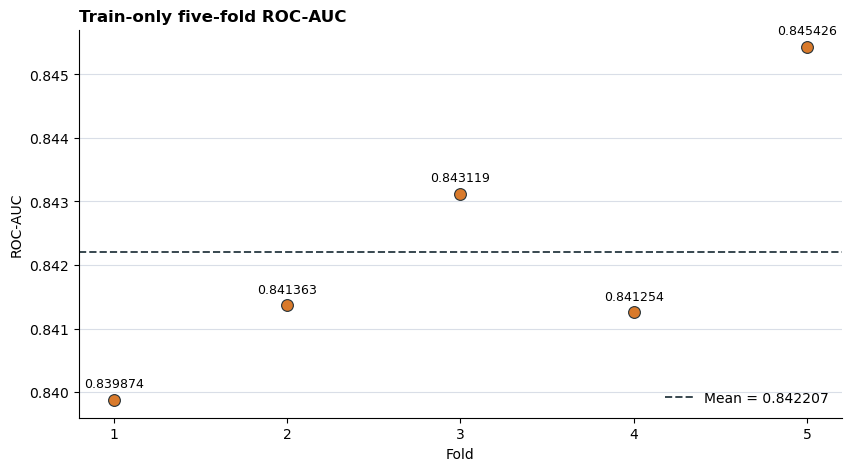

In [3]:
display(Markdown("## Train-only cross-validation\n\nNăm fold dùng fresh balanced RF estimators và fold-local preprocessing. OOF coverage bao phủ 205.310 Train rows đúng một lần."))
cv = json.loads((run_dir / "cv_results.json").read_text(encoding="utf-8"))
cv_frame = cv_fold_frame(cv, model_key="rf")
cv_summary = pd.DataFrame([{
    "Mean fold ROC-AUC": review["cv"]["mean_roc_auc"],
    "Fold ROC-AUC std": review["cv"]["std_roc_auc"],
    "OOF ROC-AUC": review["cv"]["oof_roc_auc"],
    "OOF rows": review["cv"]["oof_rows"],
    "Warnings": review["cv"]["warning_count"],
}])
display(cv_summary.style.format({"Mean fold ROC-AUC": "{:.6f}", "Fold ROC-AUC std": "{:.6f}", "OOF ROC-AUC": "{:.6f}"}))
display(cv_frame)
plot_cv_roc_auc(cv_frame, model_key="rf", mean_roc_auc=review["cv"]["mean_roc_auc"]);
display(Markdown("### Fresh full-Train fit\n\nSau CV, một fresh balanced RF pipeline được fit trên toàn bộ Train và reload prediction verification đã PASS."))
full_train_result = json.loads((run_dir / "full_train_result.json").read_text(encoding="utf-8"))
full_train_table = pd.DataFrame([{
    "Train rows": review["full_train"]["fit_rows"],
    "Encoded features": review["feature_counts"]["model_input"],
    "Matrix": f"{full_train_result['matrix_format']} {full_train_result['matrix_dtype']}",
    "Finite": full_train_result["matrix_finite"],
    "Class weight": full_train_result["class_weight"],
    "Fit seconds": review["full_train"]["fit_seconds"],
    "Warnings": review["full_train"]["warning_count"],
    "Reload predictions exact": full_train_result["reload_predictions_exact"],
}])
display(full_train_table.style.format({"Fit seconds": "{:.3f}"}))

## Validation prediction và threshold

RF-08 dùng frozen full-Train pipeline cho đúng một lượt Validation inference. Threshold tối đa hóa Balanced Accuracy; tie-break lần lượt ưu tiên gần 0.5 nhất rồi threshold thấp hơn.

,selected_threshold,balanced_accuracy,fn_approved,fp_denied,recall_approved,recall_denied,tn_denied,tp_approved
0,0.712,0.767091,5219,3430,0.840952,0.69323,7751,27595


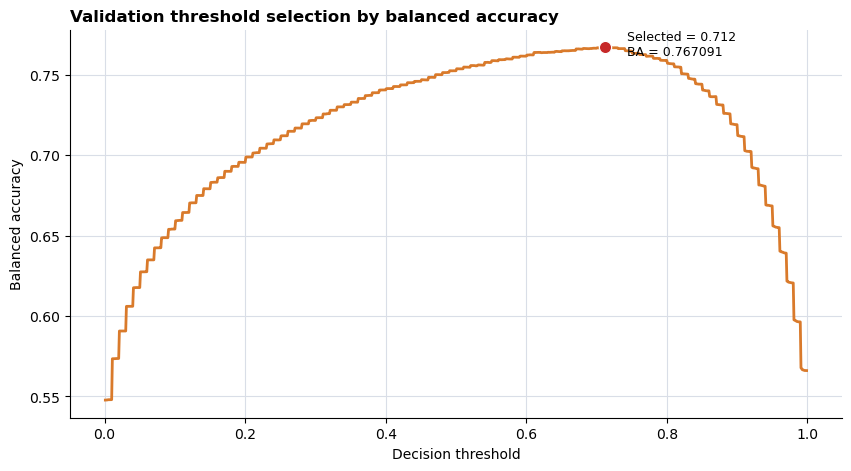

In [4]:
display(Markdown("## Validation prediction và threshold\n\nRF-08 dùng frozen full-Train pipeline cho đúng một lượt Validation inference. Threshold tối đa hóa Balanced Accuracy; tie-break lần lượt ưu tiên gần 0.5 nhất rồi threshold thấp hơn."))
threshold = json.loads((run_dir / "validation/threshold_selection.json").read_text(encoding="utf-8"))
threshold_frame = pd.read_csv(run_dir / "validation/threshold_candidates.csv")
display(pd.DataFrame([{"selected_threshold": threshold["selected_threshold"], **threshold["selected_metrics"]}]))
plot_threshold_balanced_accuracy(threshold_frame, model_key="rf", selected_threshold=threshold["selected_threshold"]);

## Frozen Test evaluation

RF-09 giữ nguyên Validation threshold và infer Test đúng một lần. Point metrics và CI dưới đây được lấy từ fresh RF 15-feature Test predictions và locked bootstrap row indices.

,metric,estimate,invalid_replicates,lower_2_5,upper_97_5,valid_replicates
0,average_precision_denied,0.746677,0,0.739908,0.753442,1000
1,balanced_accuracy,0.766911,0,0.762210,0.771524,1000
2,calibration_intercept,-0.027144,0,-0.049292,-0.006492,1000
3,calibration_slope,0.316135,2,0.280583,0.354588,998
4,f1_denied,0.641909,0,0.635380,0.648123,1000
5,precision_denied,0.598731,0,0.592022,0.605133,1000
6,recall_approved,0.842023,0,0.838335,0.845834,1000
7,recall_denied,0.691799,0,0.683568,0.700391,1000
8,roc_auc_approved,0.840940,0,0.836295,0.845353,1000
9,brier_score_approved,0.117009,0,0.115136,0.118891,1000


### Test calibration

Bảng và đồ thị so sánh mean predicted approval probability với observed approval rate trong từng probability bin. Đường chéo biểu thị perfect calibration.

,bin,count,lower_edge,mean_p_approved,observed_approval_rate,upper_edge
0,0,4355,0.000000,0.040110,0.049828,0.150000
1,1,4364,0.150000,0.360759,0.450275,0.540000
2,2,4219,0.540000,0.637668,0.715098,0.720000
3,3,4492,0.720000,0.769548,0.802538,0.820000
4,4,4127,0.820000,0.847167,0.843470,0.880000
5,5,4841,0.880000,0.901968,0.873993,0.926594
6,6,3997,0.926594,0.940967,0.892670,0.960000
7,7,3541,0.960000,0.965653,0.917255,0.980000
8,8,10060,0.980000,0.993155,0.942644,1.000000


## Takeaways
- RF-07 đến RF-10 cùng lineage `rf_final_15f_20261002_01` đã PASS và reporting status là `COMPLETE`.
- Test ROC-AUC = **0.840940**; Balanced Accuracy = **0.766911**.
- Validation threshold được khóa ở **0.712**; CI dùng 1.000 bootstrap replicates, với số replicate hợp lệ được báo riêng theo metric.
- Kết quả này chỉ mô tả hiệu năng trên cohort HMDA đã chốt; không phải bằng chứng nhân quả, pháp lý hoặc đánh giá creditworthiness.

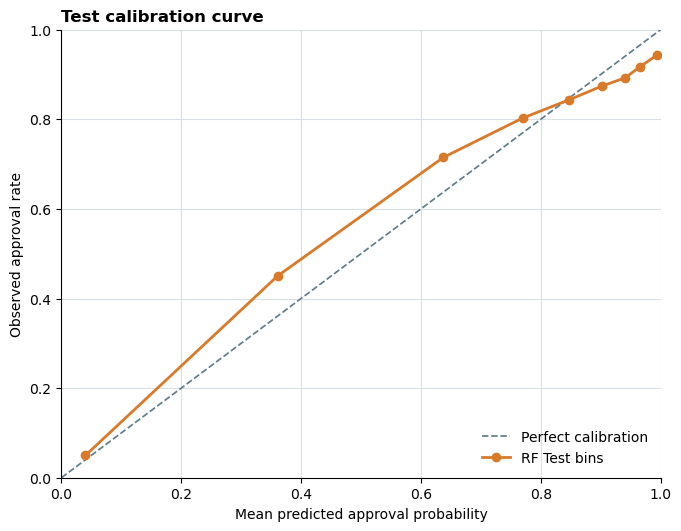

In [5]:
display(Markdown("## Frozen Test evaluation\n\nRF-09 giữ nguyên Validation threshold và infer Test đúng một lần. Point metrics và CI dưới đây được lấy từ fresh RF 15-feature Test predictions và locked bootstrap row indices."))
test_metrics = json.loads((run_dir / "test/rq1_test_metrics.json").read_text(encoding="utf-8"))
metric_rows = []
for metric, estimate in review["test"]["point_metrics"].items():
    interval = review["test"]["confidence_intervals_95_percentile"][metric]
    metric_rows.append({"metric": metric, "estimate": estimate, **interval})
metric_table = pd.DataFrame(metric_rows)
display(metric_table.style.format({"estimate": "{:.6f}", "lower_2_5": "{:.6f}", "upper_97_5": "{:.6f}"}))
display(Markdown("### Test calibration\n\nBảng và đồ thị so sánh mean predicted approval probability với observed approval rate trong từng probability bin. Đường chéo biểu thị perfect calibration."))
display(pd.DataFrame(review["test"]["calibration_curve"]))
figure, axis = plot_calibration_curve(review["test"]["calibration_curve"], model_key="rf")
display(Markdown(
    "## Takeaways\n"
    f"- RF-07 đến RF-10 cùng lineage `{run_id}` đã PASS và reporting status là `COMPLETE`.\n"
    f"- Test ROC-AUC = **{review['test']['point_metrics']['roc_auc_approved']:.6f}**; Balanced Accuracy = **{review['test']['point_metrics']['balanced_accuracy']:.6f}**.\n"
    f"- Validation threshold được khóa ở **{review['test']['threshold']:.3f}**; CI dùng 1.000 bootstrap replicates, với số replicate hợp lệ được báo riêng theo metric.\n"
    "- Kết quả này chỉ mô tả hiệu năng trên cohort HMDA đã chốt; không phải bằng chứng nhân quả, pháp lý hoặc đánh giá creditworthiness."
))